# Extended Analysis

Runs the extended benchmark comparison and the allocation + tree heuristic ablation on the saved extended results.


In [1]:
from pathlib import Path
import importlib
import sys

import matplotlib.pyplot as plt
from IPython.display import Markdown, display

# Resolve paths whether the notebook is launched from the repository root or this folder.
working_directory = Path.cwd().resolve()
PROJECT_DIRECTORY = (
    working_directory / "min-error-sequential"
    if (working_directory / "min-error-sequential").is_dir()
    else working_directory
)
MODULE_DIRECTORY = PROJECT_DIRECTORY
SOURCE_DIRECTORY = PROJECT_DIRECTORY / "src"
if str(SOURCE_DIRECTORY) not in sys.path:
    sys.path.insert(0, str(SOURCE_DIRECTORY))

# Reload algorithm code first so comparison_analysis sees the latest heuristic signature.
import heuristic
heuristic = importlib.reload(heuristic)

import approximate_comparison_analysis as comparison_analysis
comparison_analysis = importlib.reload(comparison_analysis)
approximate_summary = comparison_analysis.approximate_summary
field_family_summary = comparison_analysis.field_family_summary
load_approximate_results = comparison_analysis.load_approximate_results
overall_error_curve_summary = comparison_analysis.overall_error_curve_summary
runtime_by_k_summary = comparison_analysis.runtime_by_k_summary
run_approximate_dataset = comparison_analysis.run_approximate_dataset

print("Project directory:", PROJECT_DIRECTORY)
print("Source directory:", SOURCE_DIRECTORY)


Project directory: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/min-error-sequential
Source directory: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/min-error-sequential/src


## Run Settings

The `RUN_SCOPE` setting selects either the deterministic 100-case pilot sample (`"test"`) or all 2,700 expanded cases per dimension (`"full"`). Both scopes use the same generated benchmark instances; the setting only changes how many saved cases are selected for evaluation.


In [2]:
# Run the expanded one-dimensional and two-dimensional datasets.
DATASETS = ["benchmark_1d", "benchmark_2d"]

# Switch here: "test" runs 100 balanced cases; "full" runs all 2,700 cases per dataset.
RUN_SCOPE = "full"
if RUN_SCOPE not in {"test", "full"}:
    raise ValueError('RUN_SCOPE must be "test" or "full"')

REPLICATES_PER_CELL = None
TEST_CASES_PER_DATASET = 100
CASE_LIMIT = None if RUN_SCOPE == "full" else TEST_CASES_PER_DATASET
CASE_SAMPLE_SEED = 20260820
PROGRESS_EVERY = 25

# Keep scalable results separate from the compact exact comparison.
RESULTS_ROOT = MODULE_DIRECTORY / "results" / "cmp_extended"

print("Run scope:", RUN_SCOPE)
print("Cases per dataset:", "2,700" if RUN_SCOPE == "full" else TEST_CASES_PER_DATASET)
print("Test-case sampling seed:", CASE_SAMPLE_SEED)
print("Results directory:", RESULTS_ROOT)


Run scope: full
Cases per dataset: 2,700
Test-case sampling seed: 20260820
Results directory: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/min-error-sequential/results/cmp_extended


## Algorithm Configuration



In [3]:
# Greedy has no optional tuning parameters.
GREEDY_PARAMETERS = {}

# Configure allocation VND and final beam-tree construction.
HEURISTIC_PARAMETERS = {
    "beam_width": 3,
    "max_iterations": 30,
    "initialization": "near_uniform",
    "move_sizes": (1, 2, 3),
}

# Reproduce the near-uniform remainder placement.
UNIFORM_PARAMETERS = {"random_seed": 0}

# Reproduce case-specific random allocations and decision trees.
RANDOM_PARAMETERS = {"random_seed": 0}

print("Greedy parameters:", GREEDY_PARAMETERS)
print("Heuristic parameters:", HEURISTIC_PARAMETERS)
print("Uniform parameters:", UNIFORM_PARAMETERS)


Greedy parameters: {}
Heuristic parameters: {'beam_width': 3, 'max_iterations': 30, 'initialization': 'near_uniform', 'move_sizes': (1, 2, 3)}
Uniform parameters: {'random_seed': 0}


In [4]:
# Reload the runner so an open kernel cannot reuse an older case selector.
comparison_analysis = importlib.reload(comparison_analysis)
run_approximate_dataset = comparison_analysis.run_approximate_dataset

records_by_dataset = {}
for dataset in DATASETS:
    display(Markdown(f"### Running `{dataset}`"))
    records_by_dataset[dataset] = run_approximate_dataset(
        dataset,
        replicates_per_cell=REPLICATES_PER_CELL,
        results_root=RESULTS_ROOT,
        greedy_parameters=GREEDY_PARAMETERS,
        heuristic_parameters=HEURISTIC_PARAMETERS,
        uniform_parameters=UNIFORM_PARAMETERS,
        random_parameters=RANDOM_PARAMETERS,
        progress_every=PROGRESS_EVERY,
        case_limit=CASE_LIMIT,
        case_sample_seed=CASE_SAMPLE_SEED,
    )


### Running `benchmark_1d`

benchmark_1d: completed case 1/2700 (gaussian, K=3, M=3)
benchmark_1d: completed case 25/2700 (gaussian, K=3, M=3)
benchmark_1d: completed case 50/2700 (gaussian, K=3, M=4)
benchmark_1d: completed case 75/2700 (gaussian, K=3, M=5)
benchmark_1d: completed case 100/2700 (gaussian, K=3, M=6)
benchmark_1d: completed case 125/2700 (gaussian, K=3, M=7)
benchmark_1d: completed case 150/2700 (gaussian, K=3, M=7)
benchmark_1d: completed case 175/2700 (gaussian, K=3, M=8)
benchmark_1d: completed case 200/2700 (gaussian, K=4, M=3)
benchmark_1d: completed case 225/2700 (gaussian, K=4, M=4)
benchmark_1d: completed case 250/2700 (gaussian, K=4, M=5)
benchmark_1d: completed case 275/2700 (gaussian, K=4, M=6)
benchmark_1d: completed case 300/2700 (gaussian, K=4, M=6)
benchmark_1d: completed case 325/2700 (gaussian, K=4, M=7)
benchmark_1d: completed case 350/2700 (gaussian, K=4, M=8)
benchmark_1d: completed case 375/2700 (gaussian, K=5, M=3)
benchmark_1d: completed case 400/2700 (gaussian, K=5, M=4)
be

### Running `benchmark_2d`

benchmark_2d: completed case 1/2700 (gaussian, K=3, M=3)
benchmark_2d: completed case 25/2700 (gaussian, K=3, M=3)
benchmark_2d: completed case 50/2700 (gaussian, K=3, M=4)
benchmark_2d: completed case 75/2700 (gaussian, K=3, M=5)
benchmark_2d: completed case 100/2700 (gaussian, K=3, M=6)
benchmark_2d: completed case 125/2700 (gaussian, K=3, M=7)
benchmark_2d: completed case 150/2700 (gaussian, K=3, M=7)
benchmark_2d: completed case 175/2700 (gaussian, K=3, M=8)
benchmark_2d: completed case 200/2700 (gaussian, K=4, M=3)
benchmark_2d: completed case 225/2700 (gaussian, K=4, M=4)
benchmark_2d: completed case 250/2700 (gaussian, K=4, M=5)
benchmark_2d: completed case 275/2700 (gaussian, K=4, M=6)
benchmark_2d: completed case 300/2700 (gaussian, K=4, M=6)
benchmark_2d: completed case 325/2700 (gaussian, K=4, M=7)
benchmark_2d: completed case 350/2700 (gaussian, K=4, M=8)
benchmark_2d: completed case 375/2700 (gaussian, K=5, M=3)
benchmark_2d: completed case 400/2700 (gaussian, K=5, M=4)
be

## Numerical Summary

This table summarizes surrogate final error and runtime for each scalable method. It is a compact check on the full set of records used by the subsequent plots.


In [5]:
# Load saved records when the expensive run cell was intentionally skipped.
if "records_by_dataset" not in globals():
    records_by_dataset = {
        dataset: load_approximate_results(
            dataset, results_root=RESULTS_ROOT, run_scope=RUN_SCOPE
        )
        for dataset in DATASETS
    }

summary_lines = [
    "| Dataset | Algorithm | Cases | Budget runs | Mean surrogate error | Maximum surrogate error | Mean runtime (s) | Median runtime (s) |",
    "|---|---|---:|---:|---:|---:|---:|---:|",
]
for dataset, records in records_by_dataset.items():
    for row in approximate_summary(records):
        summary_lines.append(
            f"| {dataset} | {row['algorithm']} | {row['cases']} | {row['runs']} | "
            f"{row['mean_error']:.5f} | {row['maximum_error']:.5f} | "
            f"{row['mean_seconds']:.5f} | {row['median_seconds']:.5f} |"
        )

display(Markdown("\n".join(summary_lines)))


| Dataset | Algorithm | Cases | Budget runs | Mean surrogate error | Maximum surrogate error | Mean runtime (s) | Median runtime (s) |
|---|---|---:|---:|---:|---:|---:|---:|
| benchmark_1d | Greedy | 2700 | 10728 | 0.18594 | 0.78391 | 0.00884 | 0.00485 |
| benchmark_1d | Heuristic | 2700 | 10728 | 0.15619 | 0.71653 | 0.02037 | 0.00916 |
| benchmark_1d | Uniform | 2700 | 10728 | 0.45701 | 0.83552 | 0.00066 | 0.00053 |
| benchmark_1d | Random | 2700 | 10728 | 0.38942 | 0.80707 | 0.00065 | 0.00053 |
| benchmark_2d | Greedy | 2700 | 10732 | 0.21706 | 0.78370 | 0.00885 | 0.00483 |
| benchmark_2d | Heuristic | 2700 | 10732 | 0.18771 | 0.77300 | 0.02064 | 0.00900 |
| benchmark_2d | Uniform | 2700 | 10732 | 0.48227 | 0.84722 | 0.00068 | 0.00054 |
| benchmark_2d | Random | 2700 | 10732 | 0.42461 | 0.85475 | 0.00066 | 0.00054 |

## Overall Surrogate-Error Curve Summary

Each row matches one point in the overall mean surrogate-error curves. The final column reports the surrogate-error reduction achieved by the Allocation + tree heuristic relative to Greedy; positive values mean the Allocation + tree heuristic is better.


In [6]:
curve_summary_lines = [
    r"| Dimension | Budget level | Mean $N/N_{\min}^{opt}$ | Greedy mean surrogate error | Heuristic mean surrogate error | Uniform mean surrogate error | Random mean surrogate error | Heuristic reduction from Greedy |",
    "|---|---:|---:|---:|---:|---:|---:|---:|",
]
for records in records_by_dataset.values():
    for row in overall_error_curve_summary(records):
        curve_summary_lines.append(
            f"| {row['dimension']} | {row['budget_level']} | "
            f"{row['mean_budget_fraction']:.3f} | "
            f"{row['greedy_mean_error']:.4f} | "
            f"{row['heuristic_mean_error']:.4f} | "
            f"{row['uniform_mean_error']:.4f} | "
            f"{row['random_mean_error']:.4f} | "
            f"{row['error_reduction']:.4f} "
            f"({row['error_reduction_percent']:.1f}%) |"
        )

display(Markdown("\n".join(curve_summary_lines)))


| Dimension | Budget level | Mean $N/N_{\min}^{opt}$ | Greedy mean surrogate error | Heuristic mean surrogate error | Uniform mean surrogate error | Random mean surrogate error | Heuristic reduction from Greedy |
|---|---:|---:|---:|---:|---:|---:|---:|
| 1D | 1 | 0.166 | 0.3685 | 0.3216 | 0.5941 | 0.5446 | 0.0469 (12.7%) |
| 1D | 2 | 0.315 | 0.1873 | 0.1605 | 0.5062 | 0.4201 | 0.0269 (14.4%) |
| 1D | 3 | 0.471 | 0.1096 | 0.0873 | 0.3976 | 0.3261 | 0.0223 (20.3%) |
| 1D | 4 | 0.602 | 0.0755 | 0.0527 | 0.3269 | 0.2638 | 0.0228 (30.2%) |
| 2D | 1 | 0.159 | 0.4061 | 0.3607 | 0.6098 | 0.5676 | 0.0455 (11.2%) |
| 2D | 2 | 0.297 | 0.2232 | 0.1955 | 0.5253 | 0.4576 | 0.0277 (12.4%) |
| 2D | 3 | 0.444 | 0.1375 | 0.1155 | 0.4301 | 0.3651 | 0.0220 (16.0%) |
| 2D | 4 | 0.564 | 0.0986 | 0.0764 | 0.3610 | 0.3052 | 0.0221 (22.5%) |

## Runtime Summary by Number of Fields



In [7]:
runtime_summary_lines = [
    "| Dimension | $K$ | Greedy median runtime (s) | Heuristic median runtime (s) | Uniform median runtime (s) | Random median runtime (s) | Heuristic / Greedy runtime |",
    "|---|---:|---:|---:|---:|---:|---:|",
]
for records in records_by_dataset.values():
    for row in runtime_by_k_summary(records):
        runtime_summary_lines.append(
            f"| {row['dimension']} | {row['K']} | "
            f"{row['greedy_median_seconds']:.6f} | "
            f"{row['heuristic_median_seconds']:.6f} | "
            f"{row['uniform_median_seconds']:.6f} | "
            f"{row['random_median_seconds']:.6f} | "
            f"{row['heuristic_to_greedy_ratio']:.2f}x |"
        )

display(Markdown("\n".join(runtime_summary_lines)))


| Dimension | $K$ | Greedy median runtime (s) | Heuristic median runtime (s) | Uniform median runtime (s) | Random median runtime (s) | Heuristic / Greedy runtime |
|---|---:|---:|---:|---:|---:|---:|
| 1D | 3 | 0.000819 | 0.000962 | 0.000133 | 0.000134 | 1.29x |
| 1D | 4 | 0.002354 | 0.002921 | 0.000309 | 0.000308 | 1.43x |
| 1D | 5 | 0.004987 | 0.006882 | 0.000532 | 0.000530 | 1.60x |
| 1D | 6 | 0.009544 | 0.017834 | 0.000843 | 0.000840 | 1.92x |
| 1D | 7 | 0.018563 | 0.058858 | 0.001321 | 0.001310 | 3.00x |
| 2D | 3 | 0.000892 | 0.001055 | 0.000141 | 0.000141 | 1.30x |
| 2D | 4 | 0.002346 | 0.002832 | 0.000295 | 0.000291 | 1.42x |
| 2D | 5 | 0.004797 | 0.006665 | 0.000534 | 0.000532 | 1.60x |
| 2D | 6 | 0.009721 | 0.018066 | 0.000860 | 0.000852 | 1.93x |
| 2D | 7 | 0.018818 | 0.059654 | 0.001411 | 0.001344 | 3.02x |

## Surrogate-Error Summary by Field Family

Each row averages surrogate final error over all included $K$, $M$, sensor budgets, and replicates. The final column reports the Allocation + tree heuristic's surrogate-error reduction relative to Greedy.


In [8]:
family_summary_lines = [
    "| Dimension | Field family | Greedy mean surrogate error | Heuristic mean surrogate error | Uniform mean surrogate error | Random mean surrogate error | Heuristic reduction from Greedy |",
    "|---|---|---:|---:|---:|---:|---:|",
]
for records in records_by_dataset.values():
    for row in field_family_summary(records):
        family_summary_lines.append(
            f"| {row['dimension']} | {row['field_family']} | "
            f"{row['greedy_mean_error']:.4f} | "
            f"{row['heuristic_mean_error']:.4f} | "
            f"{row['uniform_mean_error']:.4f} | "
            f"{row['random_mean_error']:.4f} | "
            f"{row['heuristic_reduction']:.4f} "
            f"({row['heuristic_reduction_percent']:.1f}%) |"
        )

display(Markdown("\n".join(family_summary_lines)))


| Dimension | Field family | Greedy mean surrogate error | Heuristic mean surrogate error | Uniform mean surrogate error | Random mean surrogate error | Heuristic reduction from Greedy |
|---|---|---:|---:|---:|---:|---:|
| 1D | gaussian | 0.1974 | 0.1614 | 0.4778 | 0.4128 | 0.0360 (18.2%) |
| 1D | sinusoidal | 0.1056 | 0.0846 | 0.3118 | 0.2605 | 0.0210 (19.9%) |
| 1D | quadratic | 0.2532 | 0.2211 | 0.5785 | 0.4925 | 0.0321 (12.7%) |
| 2D | gaussian | 0.2744 | 0.2385 | 0.5436 | 0.5048 | 0.0360 (13.1%) |
| 2D | sinusoidal | 0.1024 | 0.0832 | 0.3024 | 0.2568 | 0.0192 (18.8%) |
| 2D | quadratic | 0.2722 | 0.2395 | 0.5974 | 0.5090 | 0.0327 (12.0%) |

## Comparison Plots

These figures report surrogate final error because this notebook evaluates the optimization objective used by the algorithms.

The detailed mean-error figure retains separate panels for each $K$. A second summarized figure shows 1D and 2D panels averaged across all included $K$, $M$, and field families. The field-family figure uses vertical boxplots and the same muted algorithm colors. The heuristic-iteration figure shows the distribution of iterations performed before stopping, with the configured maximum shown by a dashed line.


### Mean surrogate-error curves

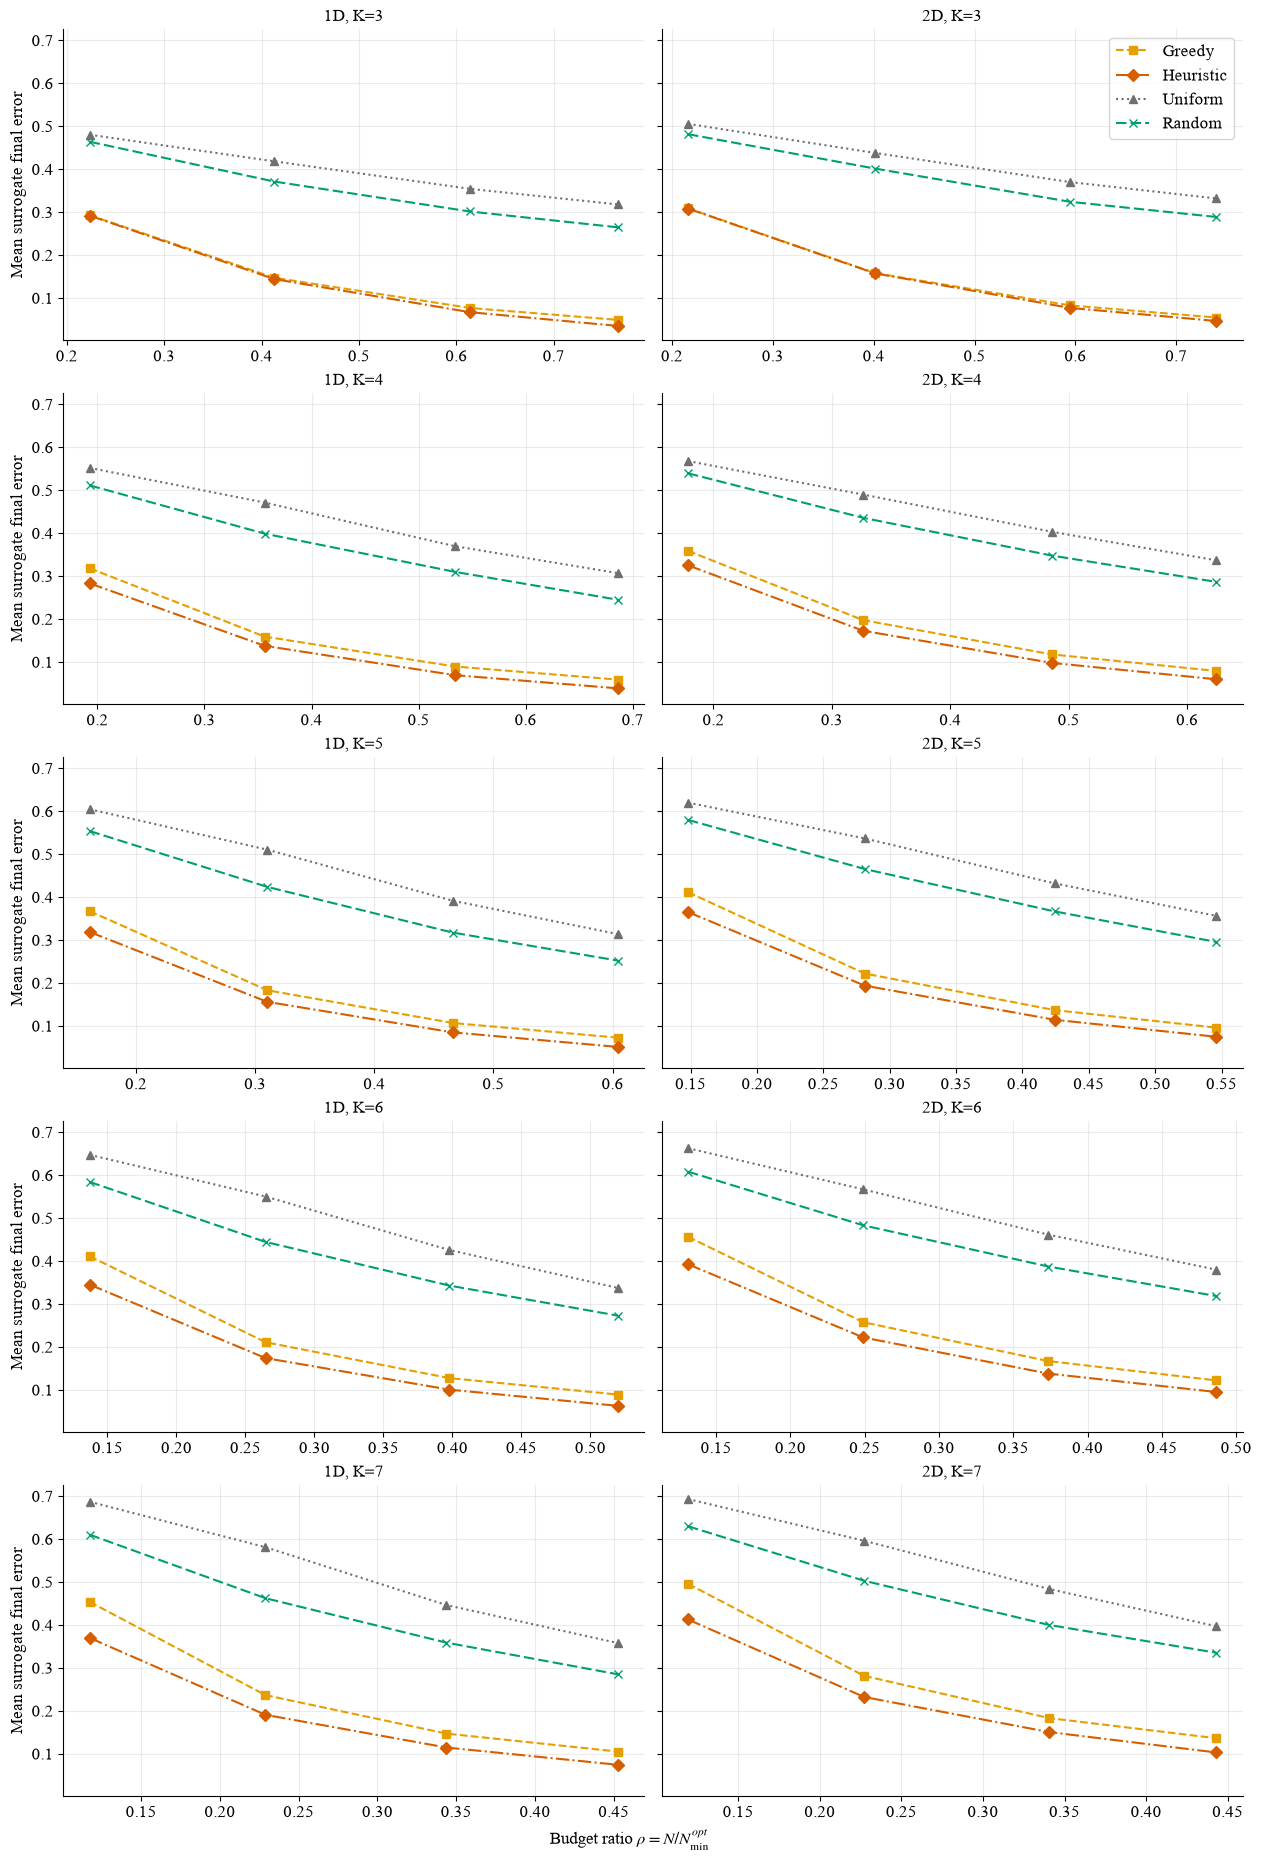

### Overall mean surrogate-error curves

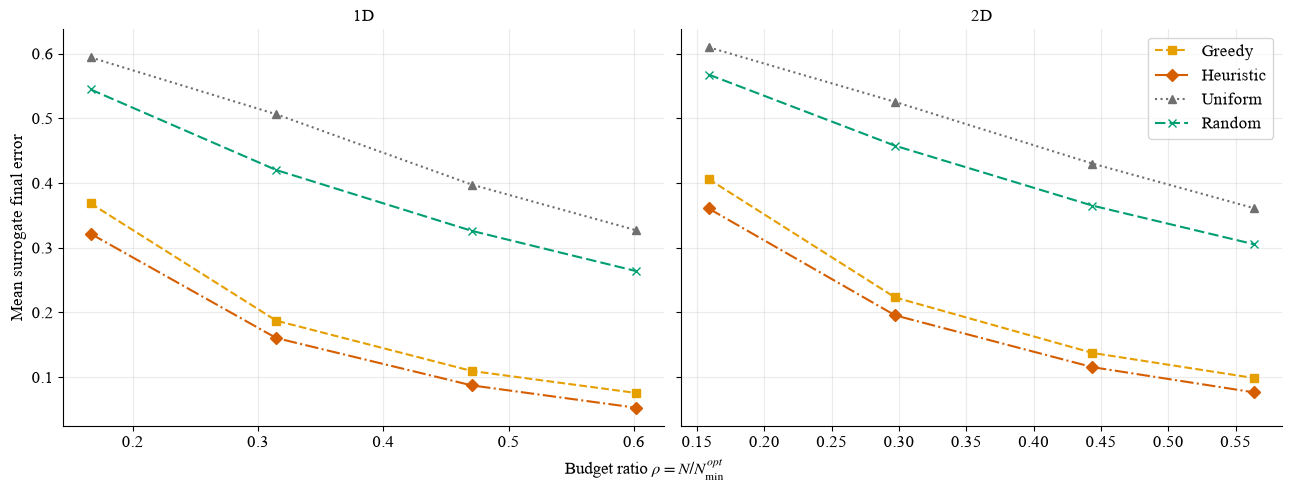

### Surrogate-error distribution by field family

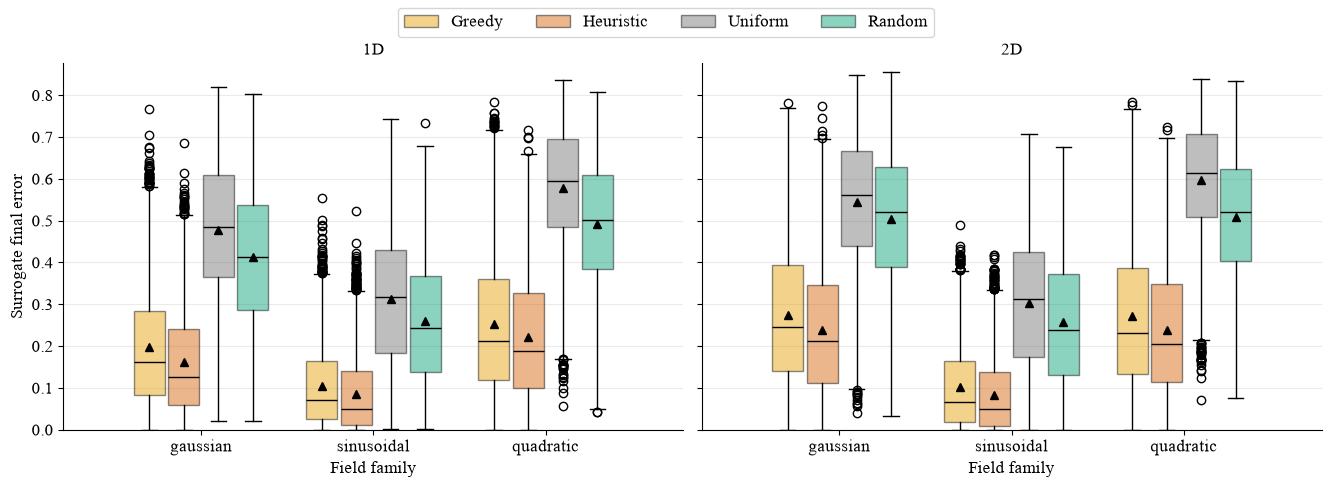

### Heuristic iteration distribution

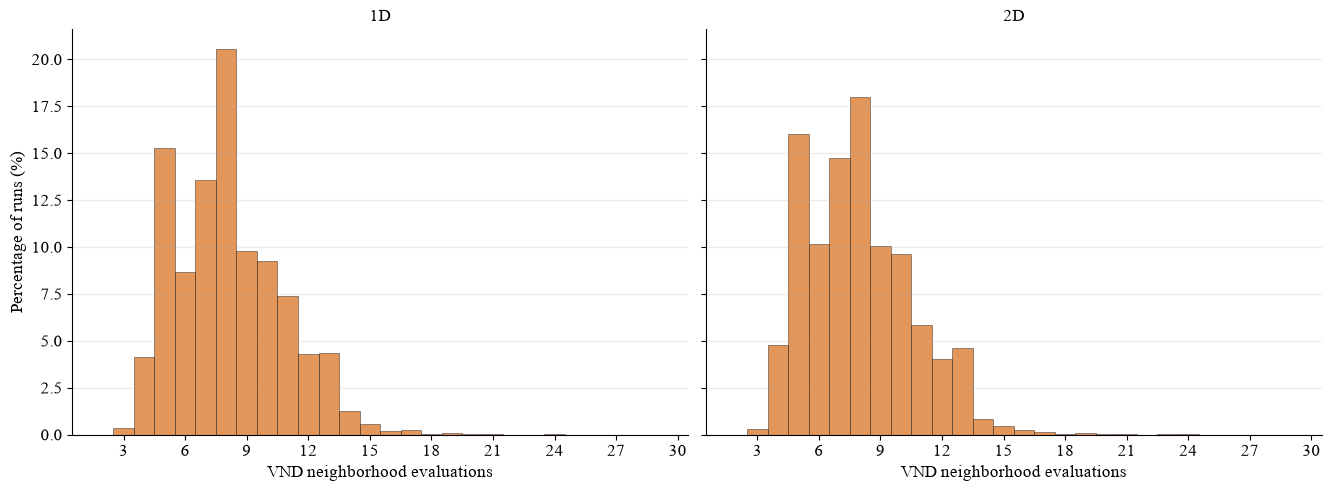

In [9]:
# Close figures left in memory by an earlier notebook run.
plt.close("all")

# Reload and apply the shared style before creating new figures.
import plot_style
plot_style = importlib.reload(plot_style)
plot_style.configure_plot_style()
# Reload plotting code so an open kernel does not reuse an older function.
comparison_analysis = importlib.reload(comparison_analysis)
# Load saved records when the expensive run cell was intentionally skipped.
if "records_by_dataset" not in globals():
    records_by_dataset = {
        dataset: comparison_analysis.load_approximate_results(
            dataset, results_root=RESULTS_ROOT, run_scope=RUN_SCOPE
        )
        for dataset in DATASETS
    }
figures = comparison_analysis.make_combined_approximate_plots(
    records_by_dataset,
    results_root=RESULTS_ROOT,
    run_scope=RUN_SCOPE,
)
for title, figure in figures:
    display(Markdown(f"### {title}"))
    display(figure)
    plt.close(figure)


## Saved Files

```text
results/cmp_extended/
├── extended_1d_<test|full>/tables/
├── extended_2d_<test|full>/tables/
└── summary_extended_1d_extended_2d_<test|full>/figures/


## Heuristic Ablation

This section compares four strategies on the extended datasets using the same saved cases and budgets. The two allocation choices are the near-uniform starting allocation and the VND allocation returned by the heuristic. Each allocation is evaluated with either greedy test ordering or beam-search test ordering. This separates the contribution of allocation search from the contribution of final tree construction.


In [10]:
import csv
from pathlib import Path
from statistics import fmean
import importlib
import sys

from IPython.display import Markdown, display
import matplotlib.pyplot as plt

# Resolve paths whether the notebook is launched from the repository root or this folder.
working_directory = Path.cwd().resolve()
PROJECT_DIRECTORY = (
    working_directory / "min-error-sequential"
    if (working_directory / "min-error-sequential").is_dir()
    else working_directory
)
SOURCE_DIRECTORY = PROJECT_DIRECTORY / "src"
if str(SOURCE_DIRECTORY) not in sys.path:
    sys.path.insert(0, str(SOURCE_DIRECTORY))

import approximate_comparison_analysis
import heuristic
import input_data
import plot_style
import uniform

approximate_comparison_analysis = importlib.reload(approximate_comparison_analysis)
heuristic = importlib.reload(heuristic)
input_data = importlib.reload(input_data)
plot_style = importlib.reload(plot_style)
uniform = importlib.reload(uniform)
plot_style.configure_plot_style()

print("Project directory:", PROJECT_DIRECTORY)
print("Source directory:", SOURCE_DIRECTORY)


Project directory: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/min-error-sequential
Source directory: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/min-error-sequential/src


## Settings

The ablation uses the same `RUN_SCOPE` convention as the extended comparison. The `"test"` scope is the deterministic pilot sample; the `"full"` scope uses the complete regenerated extended results.

In [11]:
RUN_SCOPE = "full"
DATASETS = ("benchmark_1d", "benchmark_2d")
FINAL_TREE_BEAM_WIDTH = 3
MOVE_SIZES = (1, 2, 3)

RESULTS_ROOT = PROJECT_DIRECTORY / "results" / "cmp_extended"
INPUT_ROOT = PROJECT_DIRECTORY / "inputs"
SUMMARY_DIRECTORY = RESULTS_ROOT / f"summary_heuristic_ablation_{RUN_SCOPE}"
TABLES_DIRECTORY = SUMMARY_DIRECTORY / "tables"
FIGURES_DIRECTORY = SUMMARY_DIRECTORY / "figures"
SAVE_OUTPUTS = True

print("Run scope:", RUN_SCOPE)
print("Extended results root:", RESULTS_ROOT)
print("Input root:", INPUT_ROOT)
print("Final tree beam width:", FINAL_TREE_BEAM_WIDTH)
print("Allocation move sizes:", MOVE_SIZES)
print("Save outputs:", SAVE_OUTPUTS)


Run scope: full
Extended results root: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/min-error-sequential/results/cmp_extended
Input root: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/min-error-sequential/inputs
Final tree beam width: 3
Allocation move sizes: (1, 2, 3)
Save outputs: True


In [12]:
METHOD_ORDER = (
    "Near-uniform + Greedy",
    "VND allocation + Greedy",
    "Near-uniform + Beam",
    "VND allocation + Beam",
)
METHOD_STYLES = {
    "Near-uniform + Greedy": {
        "color": plot_style.METHOD_COLORS["Uniform"],
        "linestyle": plot_style.METHOD_LINESTYLES["Uniform"],
        "marker": plot_style.METHOD_MARKERS["Uniform"],
    },
    "VND allocation + Greedy": {
        "color": plot_style.METHOD_COLORS["Greedy"],
        "linestyle": plot_style.METHOD_LINESTYLES["Greedy"],
        "marker": plot_style.METHOD_MARKERS["Greedy"],
    },
    "Near-uniform + Beam": {
        "color": plot_style.METHOD_COLORS["Optimal"],
        "linestyle": plot_style.METHOD_LINESTYLES["Optimal"],
        "marker": plot_style.METHOD_MARKERS["Optimal"],
    },
    "VND allocation + Beam": {
        "color": plot_style.METHOD_COLORS["Heuristic"],
        "linestyle": plot_style.METHOD_LINESTYLES["Heuristic"],
        "marker": plot_style.METHOD_MARKERS["Heuristic"],
    },
}


def load_extended_records(dataset):
    return approximate_comparison_analysis.load_approximate_results(
        dataset,
        results_root=RESULTS_ROOT,
        run_scope=RUN_SCOPE,
    )


def allocation_tree_errors(record):
    K = int(record["K"])
    M = int(record["M"])
    pairs = tuple((i, j) for i in range(K) for j in range(i + 1, K))
    _, _, _, pair_error_table = input_data.load_sparse_input(
        INPUT_ROOT / str(record["dataset"]) / f"{record['case']}.csv"
    )

    near_uniform_allocation = tuple(int(value) for value in record["uniform_allocation"])
    vnd_allocation = tuple(int(value) for value in record["heuristic_allocation"])

    near_uniform_locations, near_uniform_errors = heuristic._compute_pair_errors(
        pairs,
        M,
        near_uniform_allocation,
        pair_error_table,
    )
    vnd_locations, vnd_errors = heuristic._compute_pair_errors(
        pairs,
        M,
        vnd_allocation,
        pair_error_table,
    )

    near_uniform_greedy_tree = uniform._build_tree(
        tuple(range(K)),
        near_uniform_locations,
        near_uniform_errors,
    )
    vnd_greedy_tree = uniform._build_tree(
        tuple(range(K)),
        vnd_locations,
        vnd_errors,
    )
    near_uniform_beam_tree = heuristic._build_tree_with_beam_search(
        K,
        near_uniform_locations,
        near_uniform_errors,
        FINAL_TREE_BEAM_WIDTH,
    )

    return {
        "Near-uniform + Greedy": uniform._tree_error(near_uniform_greedy_tree, K),
        "VND allocation + Greedy": uniform._tree_error(vnd_greedy_tree, K),
        "Near-uniform + Beam": heuristic._tree_error(near_uniform_beam_tree, K),
        "VND allocation + Beam": float(record["heuristic_error"]),
    }


def build_ablation_records(records_by_dataset):
    ablation_records = []
    for dataset, records in records_by_dataset.items():
        display(Markdown(f"### Reconstructing ablation curves for `{dataset}`"))
        for index, record in enumerate(records, start=1):
            errors = allocation_tree_errors(record)
            ablation_records.append({
                "dataset": dataset,
                "case": str(record["case"]),
                "field_model": str(record["field_model"]),
                "dimension": int(record["spatial_dimension"]),
                "K": int(record["K"]),
                "M": int(record["M"]),
                "budget_level": int(record["budget_level"]),
                "budget_ratio": float(record["budget_fraction_of_N_min"]),
                **errors,
            })
            if index == 1 or index % 100 == 0 or index == len(records):
                print(f"{dataset}: reconstructed {index}/{len(records)}")
    return ablation_records


def mean_by_budget(records):
    rows = []
    for dimension in sorted({record["dimension"] for record in records}):
        dimension_records = [record for record in records if record["dimension"] == dimension]
        for budget_level in sorted({record["budget_level"] for record in dimension_records}):
            selected = [record for record in dimension_records if record["budget_level"] == budget_level]
            row = {
                "dimension": f"{dimension}D",
                "budget_level": budget_level,
                "budget_ratio": fmean(record["budget_ratio"] for record in selected),
                "runs": len(selected),
            }
            for method in METHOD_ORDER:
                row[method] = fmean(record[method] for record in selected)
            row["allocation_gain_with_greedy_tree"] = row["Near-uniform + Greedy"] - row["VND allocation + Greedy"]
            row["beam_gain_with_near_uniform_allocation"] = row["Near-uniform + Greedy"] - row["Near-uniform + Beam"]
            row["beam_gain_with_vnd_allocation"] = row["VND allocation + Greedy"] - row["VND allocation + Beam"]
            row["full_gain_vs_near_uniform_greedy"] = row["Near-uniform + Greedy"] - row["VND allocation + Beam"]
            rows.append(row)
    return rows


def overall_summary(records):
    rows = []
    for dimension in sorted({record["dimension"] for record in records}):
        selected = [record for record in records if record["dimension"] == dimension]
        row = {
            "dimension": f"{dimension}D",
            "runs": len(selected),
        }
        for method in METHOD_ORDER:
            row[method] = fmean(record[method] for record in selected)
        row["allocation_gain_with_greedy_tree"] = row["Near-uniform + Greedy"] - row["VND allocation + Greedy"]
        row["beam_gain_with_near_uniform_allocation"] = row["Near-uniform + Greedy"] - row["Near-uniform + Beam"]
        row["beam_gain_with_vnd_allocation"] = row["VND allocation + Greedy"] - row["VND allocation + Beam"]
        row["full_gain_vs_near_uniform_greedy"] = row["Near-uniform + Greedy"] - row["VND allocation + Beam"]
        rows.append(row)
    return rows


def markdown_table(rows, columns, formats):
    header = "| " + " | ".join(label for label, _ in columns) + " |"
    separator = "|" + "|".join("---:" if key in formats else "---" for _, key in columns) + "|"
    body = []
    for row in rows:
        values = []
        for _, key in columns:
            formatter = formats.get(key)
            values.append(formatter(row[key]) if formatter else str(row[key]))
        body.append("| " + " | ".join(values) + " |")
    return "\n".join([header, separator, *body])


def write_rows_csv(path, rows):
    if not rows:
        raise ValueError(f"No rows to write: {path}")
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open("w", encoding="utf-8", newline="") as output_file:
        writer = csv.DictWriter(output_file, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)

In [13]:
records_by_dataset = {dataset: load_extended_records(dataset) for dataset in DATASETS}
ablation_records = build_ablation_records(records_by_dataset)

summary_rows = overall_summary(ablation_records)
budget_rows = mean_by_budget(ablation_records)

if SAVE_OUTPUTS:
    write_rows_csv(TABLES_DIRECTORY / "overall_summary.csv", summary_rows)
    write_rows_csv(TABLES_DIRECTORY / "budget_summary.csv", budget_rows)
    print("Saved ablation tables under:", TABLES_DIRECTORY)

common_formats = {
    "runs": lambda value: f"{int(value)}",
    "Near-uniform + Greedy": lambda value: f"{value:.5f}",
    "VND allocation + Greedy": lambda value: f"{value:.5f}",
    "Near-uniform + Beam": lambda value: f"{value:.5f}",
    "VND allocation + Beam": lambda value: f"{value:.5f}",
    "allocation_gain_with_greedy_tree": lambda value: f"{value:.5f}",
    "beam_gain_with_near_uniform_allocation": lambda value: f"{value:.5f}",
    "beam_gain_with_vnd_allocation": lambda value: f"{value:.5f}",
    "full_gain_vs_near_uniform_greedy": lambda value: f"{value:.5f}",
}

common_columns = (
    ("Near-uniform + Greedy", "Near-uniform + Greedy"),
    ("VND allocation + Greedy", "VND allocation + Greedy"),
    ("Near-uniform + Beam", "Near-uniform + Beam"),
    ("VND allocation + Beam", "VND allocation + Beam"),
    ("Allocation gain, greedy tree", "allocation_gain_with_greedy_tree"),
    ("Beam gain, near-uniform allocation", "beam_gain_with_near_uniform_allocation"),
    ("Beam gain, VND allocation", "beam_gain_with_vnd_allocation"),
    ("Full gain", "full_gain_vs_near_uniform_greedy"),
)

display(Markdown("### Overall Ablation Summary"))
display(Markdown(markdown_table(
    summary_rows,
    (
        ("Dimension", "dimension"),
        ("Runs", "runs"),
        *common_columns,
    ),
    common_formats,
)))

display(Markdown("### Ablation Summary by Budget"))
display(Markdown(markdown_table(
    budget_rows,
    (
        ("Dimension", "dimension"),
        ("Budget level", "budget_level"),
        ("Budget ratio", "budget_ratio"),
        ("Runs", "runs"),
        *common_columns,
    ),
    {
        **common_formats,
        "budget_level": lambda value: f"{int(value)}",
        "budget_ratio": lambda value: f"{value:.3f}",
    },
)))


### Reconstructing ablation curves for `benchmark_1d`

benchmark_1d: reconstructed 1/10728
benchmark_1d: reconstructed 100/10728
benchmark_1d: reconstructed 200/10728
benchmark_1d: reconstructed 300/10728
benchmark_1d: reconstructed 400/10728
benchmark_1d: reconstructed 500/10728
benchmark_1d: reconstructed 600/10728
benchmark_1d: reconstructed 700/10728
benchmark_1d: reconstructed 800/10728
benchmark_1d: reconstructed 900/10728
benchmark_1d: reconstructed 1000/10728
benchmark_1d: reconstructed 1100/10728
benchmark_1d: reconstructed 1200/10728
benchmark_1d: reconstructed 1300/10728
benchmark_1d: reconstructed 1400/10728
benchmark_1d: reconstructed 1500/10728
benchmark_1d: reconstructed 1600/10728
benchmark_1d: reconstructed 1700/10728
benchmark_1d: reconstructed 1800/10728
benchmark_1d: reconstructed 1900/10728
benchmark_1d: reconstructed 2000/10728
benchmark_1d: reconstructed 2100/10728
benchmark_1d: reconstructed 2200/10728
benchmark_1d: reconstructed 2300/10728
benchmark_1d: reconstructed 2400/10728
benchmark_1d: reconstructed 2500/1072

### Reconstructing ablation curves for `benchmark_2d`

benchmark_2d: reconstructed 1/10732
benchmark_2d: reconstructed 100/10732
benchmark_2d: reconstructed 200/10732
benchmark_2d: reconstructed 300/10732
benchmark_2d: reconstructed 400/10732
benchmark_2d: reconstructed 500/10732
benchmark_2d: reconstructed 600/10732
benchmark_2d: reconstructed 700/10732
benchmark_2d: reconstructed 800/10732
benchmark_2d: reconstructed 900/10732
benchmark_2d: reconstructed 1000/10732
benchmark_2d: reconstructed 1100/10732
benchmark_2d: reconstructed 1200/10732
benchmark_2d: reconstructed 1300/10732
benchmark_2d: reconstructed 1400/10732
benchmark_2d: reconstructed 1500/10732
benchmark_2d: reconstructed 1600/10732
benchmark_2d: reconstructed 1700/10732
benchmark_2d: reconstructed 1800/10732
benchmark_2d: reconstructed 1900/10732
benchmark_2d: reconstructed 2000/10732
benchmark_2d: reconstructed 2100/10732
benchmark_2d: reconstructed 2200/10732
benchmark_2d: reconstructed 2300/10732
benchmark_2d: reconstructed 2400/10732
benchmark_2d: reconstructed 2500/1073

### Overall Ablation Summary

| Dimension | Runs | Near-uniform + Greedy | VND allocation + Greedy | Near-uniform + Beam | VND allocation + Beam | Allocation gain, greedy tree | Beam gain, near-uniform allocation | Beam gain, VND allocation | Full gain |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| 1D | 10728 | 0.45701 | 0.18006 | 0.42356 | 0.15619 | 0.27695 | 0.03345 | 0.02388 | 0.30083 |
| 2D | 10732 | 0.48227 | 0.21351 | 0.45089 | 0.18771 | 0.26876 | 0.03138 | 0.02580 | 0.29456 |

### Ablation Summary by Budget

| Dimension | Budget level | Budget ratio | Runs | Near-uniform + Greedy | VND allocation + Greedy | Near-uniform + Beam | VND allocation + Beam | Allocation gain, greedy tree | Beam gain, near-uniform allocation | Beam gain, VND allocation | Full gain |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| 1D | 1 | 0.166 | 2700 | 0.59411 | 0.36729 | 0.56135 | 0.32164 | 0.22682 | 0.03276 | 0.04565 | 0.27246 |
| 1D | 2 | 0.315 | 2700 | 0.50621 | 0.18470 | 0.47155 | 0.16045 | 0.32151 | 0.03466 | 0.02424 | 0.34576 |
| 1D | 3 | 0.471 | 2692 | 0.39756 | 0.10204 | 0.36252 | 0.08729 | 0.29552 | 0.03504 | 0.01475 | 0.31027 |
| 1D | 4 | 0.602 | 2636 | 0.32692 | 0.06323 | 0.29562 | 0.05270 | 0.26369 | 0.03130 | 0.01053 | 0.27422 |
| 2D | 1 | 0.159 | 2700 | 0.60977 | 0.40572 | 0.58050 | 0.36066 | 0.20405 | 0.02926 | 0.04505 | 0.24910 |
| 2D | 2 | 0.297 | 2700 | 0.52535 | 0.22234 | 0.49382 | 0.19553 | 0.30301 | 0.03153 | 0.02681 | 0.32982 |
| 2D | 3 | 0.444 | 2695 | 0.43006 | 0.13327 | 0.39698 | 0.11549 | 0.29679 | 0.03308 | 0.01779 | 0.31457 |
| 2D | 4 | 0.564 | 2637 | 0.36096 | 0.08966 | 0.32932 | 0.07643 | 0.27130 | 0.03165 | 0.01323 | 0.28454 |

Saved ablation figures under: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/min-error-sequential/results/cmp_extended/summary_heuristic_ablation_full/figures


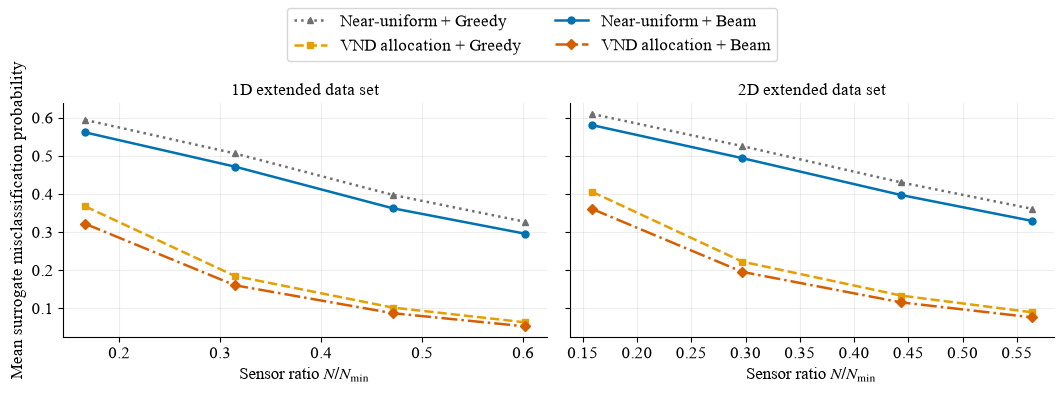

In [14]:
def plot_ablation_curves(rows):
    dimensions = sorted({row["dimension"] for row in rows})
    figure, axes = plt.subplots(1, len(dimensions), figsize=(10.8, 4.0), sharey=True)
    if len(dimensions) == 1:
        axes = [axes]
    for axis, dimension in zip(axes, dimensions):
        selected = [row for row in rows if row["dimension"] == dimension]
        for method in METHOD_ORDER:
            style = METHOD_STYLES[method]
            axis.plot(
                [row["budget_ratio"] for row in selected],
                [row[method] for row in selected],
                color=style["color"],
                linestyle=style["linestyle"],
                marker=style["marker"],
                linewidth=1.8,
                markersize=5.0,
                label=method,
            )
        axis.set_title(f"{dimension} extended data set")
        axis.set_xlabel(r"Sensor ratio $N/N_{\min}$")
        axis.grid(alpha=0.22, linewidth=0.8)
        axis.set_axisbelow(True)
    axes[0].set_ylabel("Mean surrogate misclassification probability")
    handles, labels = axes[-1].get_legend_handles_labels()
    figure.legend(handles, labels, loc="outside upper center", ncol=2)
    figure.tight_layout(rect=(0, 0, 1, 0.84))
    return figure


figure = plot_ablation_curves(budget_rows)

if SAVE_OUTPUTS:
    FIGURES_DIRECTORY.mkdir(parents=True, exist_ok=True)
    figure.savefig(FIGURES_DIRECTORY / "heuristic_ablation_extended.png", dpi=600, bbox_inches="tight")
    figure.savefig(FIGURES_DIRECTORY / "heuristic_ablation_extended.pdf", bbox_inches="tight")
    print("Saved ablation figures under:", FIGURES_DIRECTORY)

display(figure)
plt.close(figure)


## Saved Files

When `SAVE_OUTPUTS = True`, this notebook writes:

```text
results/cmp_extended/summary_heuristic_ablation_<test|full>/
├── tables/
│   ├── overall_summary.csv
│   └── budget_summary.csv
└── figures/
    ├── heuristic_ablation_extended.pdf
    └── heuristic_ablation_extended.png
```
